In [1]:
# Imports
from matplotlib import pyplot as plt
import networkx as nx

In [2]:
# function that, given a partition of n, returns the next partition of n, to cycle through all partitions. Do it as an iterator, starting at [n] and finishing at [1,1,...,1]
# Use tuples for 
def partitions(n):
    """
    Integer partitions of n, in reverse lexicographic order.
    Note that the generated output consists of the same list object,
    repeated the correct number of times; the caller must leave this
    list unchanged, and must make a copy of any partition that is
    intended to last longer than the next call into the generator.
    The algorithm follows Knuth v4 fasc3 p38 in rough outline.
    """
    if n == 0:
        yield ()
    if n <= 0:
        return
    partition = [n]
    last_nonunit = (n > 1) - 1
    while True:
        yield tuple(partition)
        if last_nonunit < 0:
            return
        if partition[last_nonunit] == 2:
            partition[last_nonunit] = 1
            partition.append(1)
            last_nonunit -= 1
            continue
        replacement = partition[last_nonunit] - 1
        total_replaced = replacement + len(partition) - last_nonunit
        reps,rest = divmod(total_replaced,replacement)
        partition[last_nonunit:] = reps*[replacement]
        if rest:
            partition.append(rest)
        last_nonunit = len(partition) - (partition[-1]==1) - 1

In [3]:
# function that, given a partition, returns the next partition for the bulgarian solitaire
def bulgarian_solitaire_step(partition):
    new_partition = []
    for part in partition:
        if part > 1:
            new_partition.append(part - 1)
    new_partition.append(len(partition))
    return tuple(sorted(new_partition, reverse=True))

In [4]:
# function that, for a given n and a given graph of partitions already searched, adds, the new partition to the graph
def add_partition_to_graph(graph, partition):
    # print(f"Calculating next partition for {partition}")
    # Find the next partition
    current_partition = partition
    while current_partition not in graph:
        next_partition = bulgarian_solitaire_step(current_partition)
        # print(f"Next partition for {current_partition} is {next_partition}")
        graph[current_partition] = (next_partition)
        current_partition = next_partition
    # print(f"Current partition is already in graph")
    # print(f"Finished calculating partitions for {partition}\n")

In [5]:
# Create the whole graph of partitions for a given n
def create_partition_graph(n):
    graph = {}
    for p in partitions(n):
        add_partition_to_graph(graph, p)
    return graph

In [6]:
def dict_to_graph(graph_dict):
    G = nx.DiGraph()
    for key, value in graph_dict.items():
        G.add_node(key)
        G.add_node(value)
        G.add_edge(key, value)
    return G

In [7]:
def pretty_layout(G):
    pos = nx.planar_layout(G, scale=1.0)
    return pos

In [8]:
import math
import random

def _closest_point_on_segment(px, py, ax, ay, bx, by):
    """Return (cx, cy, t) the closest point on segment AB to P, and the segment parameter t∈[0,1]."""
    abx, aby = bx - ax, by - ay
    apx, apy = px - ax, py - ay
    ab2 = abx*abx + aby*aby
    if ab2 == 0.0:
        return ax, ay, 0.0
    t = (apx*abx + apy*aby) / ab2
    t = 0.0 if t < 0.0 else (1.0 if t > 1.0 else t)
    cx, cy = ax + t*abx, ay + t*aby
    return cx, cy, t

def relax_with_node_edge_repulsion(
    G, pos, iterations=200,                              # how long to run
    k_rep_nodes=1.0, k_rep_edges=0.6, k_spring=0.05,     # force strengths
    spring_length=None,                                  # if None, use current lengths
    step=0.02, damping=0.85, max_force=0.5,              # integrator params
    skip_incident_edge=True,                              # don’t repel a node from its own edges
    seed=42,
    power=2
):
    """
    Force-directed relaxation with:
      - node-node Coulomb repulsion ~ 1/r^power
      - node-edge repulsion (point-to-segment) ~ 1/d^power
      - edge springs pulling endpoints to 'spring_length'
    Returns a new 'pos' dict (node -> (x,y)).
    """
    rnd = random.Random(seed)
    nodes = list(G.nodes())
    edges = list(G.edges())
    # Copy positions, add tiny jitter for coincident points
    p = {n: [float(pos[n][0]) + 1e-6*rnd.uniform(-1,1),
             float(pos[n][1]) + 1e-6*rnd.uniform(-1,1)] for n in nodes}
    v = {n: [0.0, 0.0] for n in nodes}  # velocities

    # If no spring length specified, use current edge lengths
    L0 = {}
    if spring_length is None:
        for u, vtx in edges:
            x1, y1 = p[u]; x2, y2 = p[vtx]
            L0[(u, vtx)] = math.hypot(x2 - x1, y2 - y1) or 1.0
    else:
        for e in edges:
            L0[e] = float(spring_length)

    eps = 1e-9

    for _ in range(iterations):
        # Accumulate forces
        Fx = {n: 0.0 for n in nodes}
        Fy = {n: 0.0 for n in nodes}

        # 1) node-node repulsion
        for i, u in enumerate(nodes):
            xu, yu = p[u]
            for v_idx in range(i+1, len(nodes)):
                vtx = nodes[v_idx]
                xv, yv = p[vtx]
                dx, dy = xu - xv, yu - yv
                r2 = dx*dx + dy*dy + eps
                inv = 1.0 / r2 ** (power/2)
                f = k_rep_nodes * inv
                Fx[u] += f * dx
                Fy[u] += f * dy
                Fx[vtx] -= f * dx
                Fy[vtx] -= f * dy

        # 2) node-edge repulsion (repel node u from segment (a,b))
        for u in nodes:
            xu, yu = p[u]
            for a, b in edges:
                if skip_incident_edge and (u == a or u == b):
                    continue
                xa, ya = p[a]; xb, yb = p[b]
                cx, cy, _ = _closest_point_on_segment(xu, yu, xa, ya, xb, yb)
                dx, dy = xu - cx, yu - cy
                d2 = dx*dx + dy*dy + eps
                f = k_rep_edges / d2**(power/2)
                Fx[u] += f * dx
                Fy[u] += f * dy
                # Optional: push the segment endpoints slightly too (uncomment if desired)
                # Fx[a] -= 0.5 * f * dx; Fy[a] -= 0.5 * f * dy
                # Fx[b] -= 0.5 * f * dx; Fy[b] -= 0.5 * f * dy

        # 3) edge springs
        for a, b in edges:
            xa, ya = p[a]; xb, yb = p[b]
            dx, dy = xb - xa, yb - ya
            dist = math.hypot(dx, dy) or 1.0
            # spring force along edge
            target = L0[(a, b)]
            ext = dist - target
            f = k_spring * ext / dist ** (power/2)
            fx, fy = f * dx, f * dy
            Fx[a] +=  fx; Fy[a] +=  fy
            Fx[b] += -fx; Fy[b] += -fy

        # Integrate with momentum & clamp
        for n in nodes:
            fx, fy = Fx[n], Fy[n]
            # clamp force to avoid explosions
            norm = math.hypot(fx, fy)
            if norm > max_force:
                fx *= max_force / norm
                fy *= max_force / norm

            vx, vy = v[n]
            vx = damping * vx + step * fx
            vy = damping * vy + step * fy
            v[n] = [vx, vy]
            p[n][0] += vx
            p[n][1] += vy

        # Optional: recentre to keep the cloud around (0,0)
        cx = sum(p[n][0] for n in nodes) / len(nodes)
        cy = sum(p[n][1] for n in nodes) / len(nodes)
        for n in nodes:
            p[n][0] -= cx
            p[n][1] -= cy

    # back to tuples
    return {n: (p[n][0], p[n][1]) for n in nodes}


In [9]:
# make an animation using the relaxation simulation
def animate_relaxation(G, pos, iterations=100):
    fig, ax = plt.subplots()
    nx.draw_networkx(G, pos, ax=ax, with_labels=True, arrowsize=10, font_size=6,
                     edge_color='green', arrowstyle='->', node_size=300, node_color='lightblue')
    plt.axis('off')

    for i in range(iterations):
        pos = relax_with_node_edge_repulsion(G, pos,
            iterations=1,
            k_rep_nodes=2,
            k_rep_edges=5,
            k_spring=0.4,
            spring_length=None,
            step=0.02,
            damping=0.5,
            max_force=0.5,
            skip_incident_edge=True,
            seed=90,
            power=10
        )
        ax.clear()
        nx.draw_networkx(G, pos, ax=ax, with_labels=True, arrowsize=10, font_size=6,
                         edge_color='green', arrowstyle='->', node_size=300, node_color='lightblue')
        plt.axis('off')
        plt.title(f"Iteration {i+1}")
        plt.pause(0.1)

    plt.show()




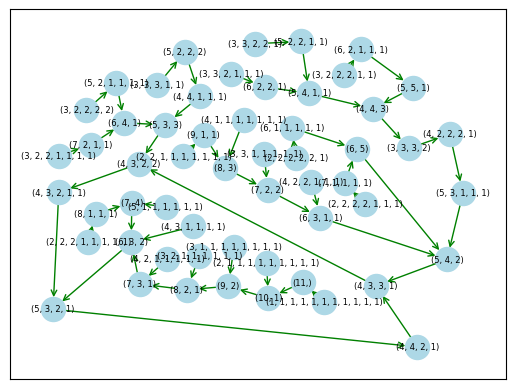

In [15]:
# plot the graph of partitions for a given n
def plot_partition_graph(n):
    graph = create_partition_graph(n)
    G = dict_to_graph(graph)
    pos = pretty_layout(G)
    pos = relax_with_node_edge_repulsion(G, pos,
        iterations=100,
        k_rep_nodes=2,
        k_rep_edges=5,
        k_spring=0.4,
        spring_length=None,
        step=0.02,
        damping=0.5,
        max_force=0.5,
        skip_incident_edge=True,
        seed=90,
        power=10
    )
    # Make arrows light grey
    nx.draw_networkx(G, pos,
        with_labels=True,
        arrowsize=10,
        font_size=6,
        edge_color='green',
        arrowstyle='->',
        node_size=300,
        node_color='lightblue')
    plt.show()
plot_partition_graph(11)